In [1]:
import torch
import torchvision
from torchvision.transforms import v2

In [10]:
import torch
import torchvision
from torchvision.transforms import v2
from torch.utils.data import random_split

transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 4

# ---- Full training set (will be split into train / val) ----
full_trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                             download=True, transform=transform)

# ---- Hold out 5,000 samples for validation ----
val_size = 5000
train_size = len(full_trainset) - val_size   # 45,000
trainset, valset = random_split(
    full_trainset, [train_size, val_size],
    generator=torch.Generator().manual_seed(42)  # fixed split for reproducibility
)

trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)
valloader = torch.utils.data.DataLoader(valset, batch_size=batch_size,
                                        shuffle=False, num_workers=2)

# ---- Test set (unchanged) ----
testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

print(f"Train: {len(trainset)} | Val: {len(valset)} | Test: {len(testset)}")

Train: 45000 | Val: 5000 | Test: 10000


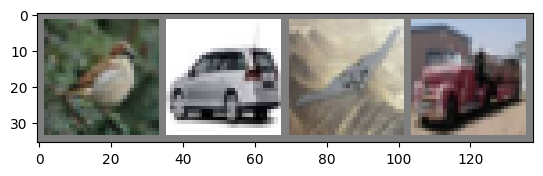

bird  car   plane truck


In [11]:
#some of the training images
import matplotlib.pyplot as plt
import numpy as np

# functions to show an image


def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


# get some random training images
dataiter = iter(trainloader)
images, labels = next(dataiter)

# show images
imshow(torchvision.utils.make_grid(images))
# print labels
print(' '.join(f'{classes[labels[j]]:5s}' for j in range(batch_size)))

In [12]:

import torch
import torch.nn as nn
import torch.nn.functional as F


class Net(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.conv3 = nn.Conv2d(16, 32, 3)

        self.fc1 = nn.Linear(32 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = F.relu(self.conv2(x))
        x = self.pool(F.relu(self.conv3(x)))

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)

        return x


net = Net()

In [13]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

In [14]:
# ---- Week 2 training loop: correct epoch loss + validation pass ----
num_epochs = 10  # adjust as needed

train_losses, train_accuracies = [], []
val_losses,   val_accuracies   = [], []

for epoch in range(num_epochs):

    # ---------------- TRAINING ----------------
    net.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in trainloader:
        optimizer.zero_grad()

        outputs = net(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        # correct epoch-level accumulation
        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc  = 100.0 * correct / total
    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    # ---------------- VALIDATION ----------------
    net.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for inputs, labels in valloader:
            outputs = net(inputs)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            val_correct += (predicted == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_acc  = 100.0 * val_correct / val_total
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    # ---------------- LOGGING ----------------
    gap = train_acc - val_acc
    print(f"Epoch [{epoch+1}/{num_epochs}] "
          f"| Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% "
          f"| Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}% "
          f"| Gap: {gap:+.2f}%")

print("Finished Training")

Epoch [1/10] | Train Loss: 1.8261 | Train Acc: 31.59% | Val Loss: 1.5775 | Val Acc: 41.72% | Gap: -10.13%
Epoch [2/10] | Train Loss: 1.4600 | Train Acc: 46.87% | Val Loss: 1.3576 | Val Acc: 50.70% | Gap: -3.83%
Epoch [3/10] | Train Loss: 1.3135 | Train Acc: 52.72% | Val Loss: 1.3270 | Val Acc: 52.60% | Gap: +0.12%
Epoch [4/10] | Train Loss: 1.2046 | Train Acc: 57.20% | Val Loss: 1.2000 | Val Acc: 57.50% | Gap: -0.30%
Epoch [5/10] | Train Loss: 1.1286 | Train Acc: 59.83% | Val Loss: 1.1445 | Val Acc: 59.92% | Gap: -0.09%
Epoch [6/10] | Train Loss: 1.0675 | Train Acc: 62.17% | Val Loss: 1.1444 | Val Acc: 60.38% | Gap: +1.79%
Epoch [7/10] | Train Loss: 1.0227 | Train Acc: 63.56% | Val Loss: 1.1008 | Val Acc: 61.98% | Gap: +1.58%
Epoch [8/10] | Train Loss: 0.9830 | Train Acc: 64.99% | Val Loss: 1.1412 | Val Acc: 60.72% | Gap: +4.27%
Epoch [9/10] | Train Loss: 0.9460 | Train Acc: 66.34% | Val Loss: 1.1834 | Val Acc: 59.96% | Gap: +6.38%
Epoch [10/10] | Train Loss: 0.9140 | Train Acc: 67.61%

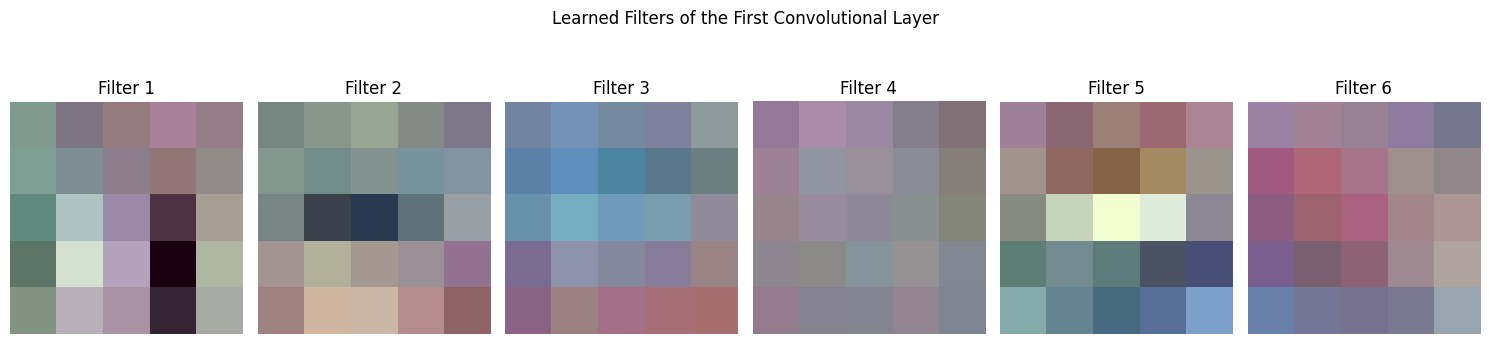

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# Get the learned weights from the first convolutional layer
filters = net.conv1.weight.data.clone()

# Move filters to CPU (if using GPU)
filters = filters.cpu()

# Normalize filters for visualization
filters = (filters - filters.min()) / (filters.max() - filters.min())

# Create a figure
fig, axes = plt.subplots(1, 6, figsize=(15, 4))

for i in range(6):
    # Get the i-th filter
    filter_img = filters[i]

    # Change dimensions from (C, H, W) to (H, W, C)
    filter_img = np.transpose(filter_img.numpy(), (1, 2, 0))

    axes[i].imshow(filter_img)
    axes[i].set_title(f'Filter {i+1}')
    axes[i].axis('off')

plt.suptitle('Learned Filters of the First Convolutional Layer')
plt.tight_layout()
plt.show()

In [16]:
#save
PATH = './cifar_net.pt'
torch.save(net.state_dict(), PATH)

In [17]:
#load
net = Net()
net.load_state_dict(torch.load(PATH, weights_only=True))

<All keys matched successfully>

In [18]:
correct = 0
total = 0
# since we're not training, we don't need to calculate the gradients for our outputs
with torch.no_grad():
    for data in testloader:
        images, labels = data
        # calculate outputs by running images through the network
        outputs = net(images)
        # the class with the highest energy is what we choose as prediction
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the network on the 10000 test images: {100 * correct // total} %')

Accuracy of the network on the 10000 test images: 60 %


In [19]:
# prepare to count predictions for each class
correct_pred = {classname: 0 for classname in classes}
total_pred = {classname: 0 for classname in classes}

# again no gradients needed
with torch.no_grad():
    for data in testloader:
        images, labels = data
        outputs = net(images)
        _, predictions = torch.max(outputs, 1)
        # collect the correct predictions for each class
        for label, prediction in zip(labels, predictions):
            if label == prediction:
                correct_pred[classes[label]] += 1
            total_pred[classes[label]] += 1


# print accuracy for each class
for classname, correct_count in correct_pred.items():
    accuracy = 100 * float(correct_count) / total_pred[classname]
    print(f'Accuracy for class: {classname:5s} is {accuracy:.1f} %')

Accuracy for class: plane is 67.7 %
Accuracy for class: car   is 71.2 %
Accuracy for class: bird  is 42.5 %
Accuracy for class: cat   is 32.4 %
Accuracy for class: deer  is 54.2 %
Accuracy for class: dog   is 58.2 %
Accuracy for class: frog  is 68.9 %
Accuracy for class: horse is 67.8 %
Accuracy for class: ship  is 72.4 %
Accuracy for class: truck is 71.1 %


000